In [2]:
import pandas as pd
from pathlib import Path

# 기존에 저장한 엑셀 파일 경로
file_path = Path(r"C:\test\충전소_목록.xlsx")

print("파일 존재 여부:", file_path.exists())

station_list = pd.read_excel(file_path)

print("충전소 개수:", station_list["충전소명"].nunique())
print("열 이름:", station_list.columns.tolist())

display(station_list.head())

파일 존재 여부: True
충전소 개수: 191
열 이름: ['번호', '충전소명']


,번호,충전소명
0,1,50+동부캠퍼스
1,2,AI 체육센터
2,3,SK허브수 인근 거주자우선주차장 볼라드형 충전소
3,4,가산 공영주차장
4,5,강남구 압구정 나들목 앞 가로등형 충전기


In [ ]:
# 1. 필요한 라이브러리 설치
%pip install rapidfuzz openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
%pip install pandas openpyxl geopy folium

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
from pathlib import Path

file_path = Path(
    r"C:\test\08_지도시각화\서울시_충전소명_191개 주소.xlsx"
)

df = pd.read_excel(file_path)

# 열 이름 공백 제거
df.columns = df.columns.astype(str).str.strip()

# 주소 빈칸 처리
for col in ["도로명", "지번"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

# 상위 10개만 테스트
df_test = df.head(10).copy()

print("전체 충전소:", len(df))
print("테스트 대상:", len(df_test))
print("열 이름:", df.columns.tolist())

display(df_test)

전체 충전소: 189
테스트 대상: 10
열 이름: ['번호', '충전소명', '도로명', '지번']


,번호,충전소명,도로명,지번
0,1,50+동부캠퍼스,서울 광진구 능동로3길 73,
1,2,AI 체육센터,서울 서초구 태봉로 108,
2,3,SK허브수 인근 거주자우선주차장 볼라드형 충전소,서울특별시 구로구 구일로10길 27,
3,4,가산 공영주차장,서울특별시 금천구 시흥대로153길 53 가산동 공영주차장,
4,5,강남구 압구정 나들목 앞 가로등형 충전기,,
5,6,강남운전면허시험장,서울특별시 강남구 테헤란로114길 23 강남운전면허시험장,
6,7,강남주민편익시설(가로등),서울 강남구 남부순환로 3318 강남주민편익시설,
7,8,강동구청,서울특별시 강동구 성내로 25 강동구청,
8,9,강동구청 제2구민체육센터,서울 강동구 아리수로93길 51,
9,10,강동문화재단,서울특별시 강동구 동남로 870,


In [ ]:
import requests
import pandas as pd

# 여기에 복사한 REST API 키 입력
KAKAO_API_KEY = "902947b7231b46b8948746a89ff58b32"

def get_coordinates(address):
    url = "https://dapi.kakao.com/v2/local/search/address.json"

    headers = {
        "Authorization": f"KakaoAK {KAKAO_API_KEY}"
    }

    params = {
        "query": address
    }

    response = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=10
    )

    response.raise_for_status()
    data = response.json()

    if data["documents"]:
        result = data["documents"][0]

        return pd.Series({
            "위도": float(result["y"]),
            "경도": float(result["x"])
        })

    return pd.Series({
        "위도": None,
        "경도": None
    })

In [ ]:
# 위도·경도가 없는 충전소만 추출
df["위도"] = pd.to_numeric(df["위도"], errors="coerce")
df["경도"] = pd.to_numeric(df["경도"], errors="coerce")

df_failed = df[
    df["위도"].isna() | df["경도"].isna()
]

# 충전소명과 주소만 화면에 표시
display(
    df_failed[["충전소명", "도로명", "지번"]]
)

print("좌표 변환 실패:", len(df_failed), "개")

,충전소명,도로명,지번
4,강남구 압구정 나들목 앞 가로등형 충전기,,
24,남산청사,,
50,마들스포츠타운,,
103,송월동차고지,,
107,수락산디자인 노상공영주차장(가로등),,
114,신대방동 신라스테이 거주자주차장(가로등),,
150,적선동 공영주차장,,
176,하월곡동 거주자우선주차장,,


좌표 변환 실패: 8 개


원본 데이터 개수: 189
열 이름: ['번호', '충전소명', '도로명', '지번', '위도', '경도']
좌표가 유효한 충전소 수: 181
좌표가 없는 행 수: 8


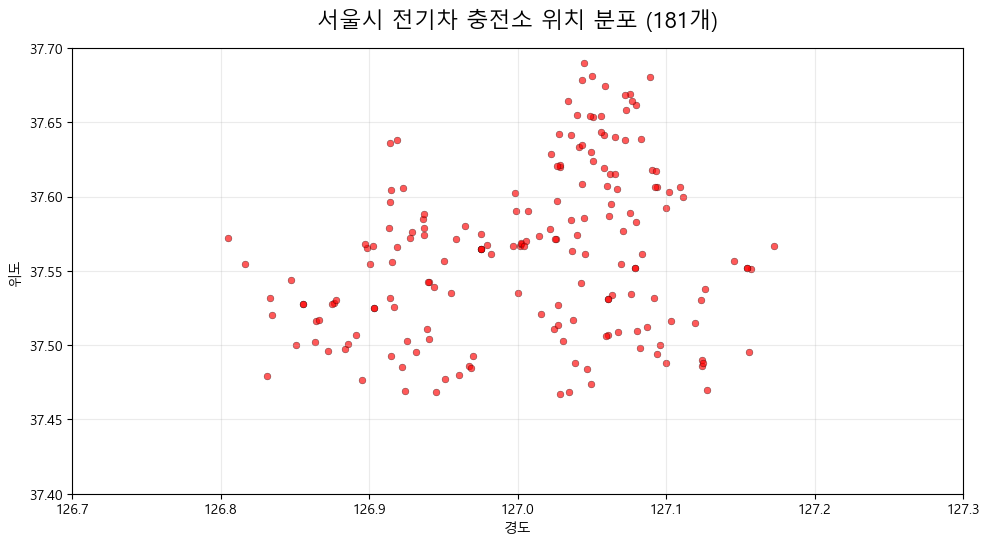

지도 이미지 저장 완료!
저장 위치: C:\test\08_지도시각화\서울시_충전소_위치분포.png


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =====================================
# 1. 기본 설정
# =====================================

# 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 엑셀 파일 경로
file_path = Path(
    r"C:\test\08_지도시각화\서울시_충전소_위경도.xlsx"
)

# 결과 이미지 저장 경로
output_path = Path(
    r"C:\test\08_지도시각화\서울시_충전소_위치분포.png"
)

# =====================================
# 2. 데이터 불러오기
# =====================================

if not file_path.exists():
    raise FileNotFoundError(
        f"엑셀 파일을 찾을 수 없습니다:\n{file_path}"
    )

df = pd.read_excel(file_path)

print("원본 데이터 개수:", len(df))
print("열 이름:", df.columns.tolist())

# =====================================
# 3. 위도와 경도 확인 및 정리
# =====================================

required_columns = ["충전소명", "위도", "경도"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"엑셀에 다음 열이 없습니다: {missing_columns}"
    )

# 위도와 경도를 숫자로 변환
df["위도"] = pd.to_numeric(df["위도"], errors="coerce")
df["경도"] = pd.to_numeric(df["경도"], errors="coerce")

# 좌표가 없는 행 제거
df_map = df.dropna(subset=["위도", "경도"]).copy()

# 서울의 대략적인 좌표 범위만 사용
df_map = df_map[
    df_map["위도"].between(37.4, 37.7)
    & df_map["경도"].between(126.7, 127.3)
].copy()

print("좌표가 유효한 충전소 수:", len(df_map))
print("좌표가 없는 행 수:", len(df) - len(df.dropna(subset=["위도", "경도"])))

if df_map.empty:
    raise ValueError(
        "표시할 좌표가 없습니다. 위도와 경도 열의 값을 확인해 주세요."
    )

# =====================================
# 4. 충전소 위치 분포도 그리기
# =====================================

fig, ax = plt.subplots(figsize=(10, 12))

ax.scatter(
    df_map["경도"],
    df_map["위도"],
    s=24,
    color="red",
    alpha=0.65,
    edgecolors="black",
    linewidths=0.3
)

# 서울 중심 좌표를 기준으로 보기
ax.set_xlim(126.7, 127.3)
ax.set_ylim(37.4, 37.7)

ax.set_title(
    f"서울시 전기차 충전소 위치 분포 ({len(df_map)}개)",
    fontsize=16,
    pad=15
)

ax.set_xlabel("경도")
ax.set_ylabel("위도")

ax.grid(alpha=0.25)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()

# =====================================
# 5. 이미지 저장 및 화면 표시
# =====================================

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("지도 이미지 저장 완료!")
print("저장 위치:", output_path)


서울 경계 데이터 불러오기 완료
지도에 표시할 충전소: 181


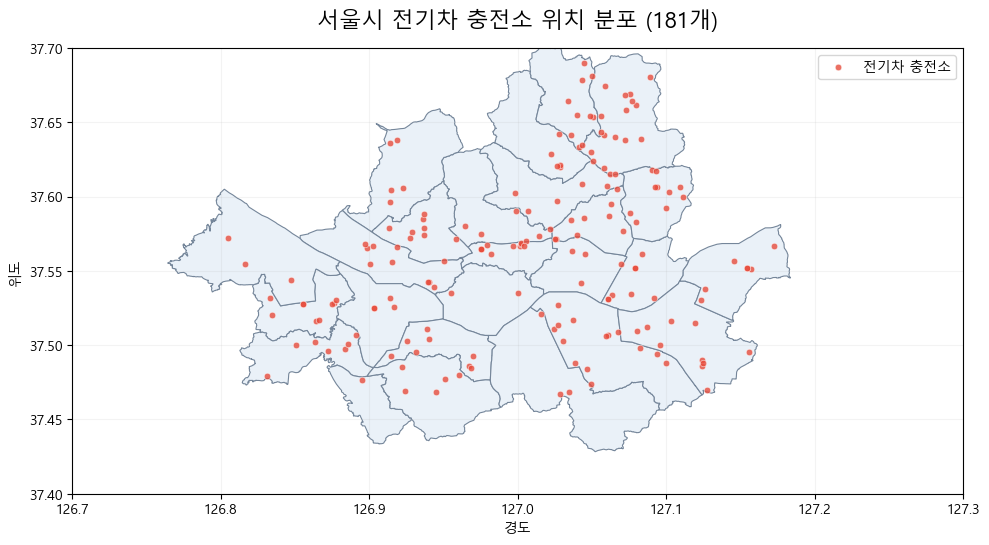

지도 이미지 저장 완료: C:\test\08_지도시각화\서울시_충전소_지도.png


In [4]:
import pandas as pd
from pathlib import Path

# 위도·경도 파일
location_path = Path(
    r"C:\test\08_지도시각화\서울시_충전소_위경도.xlsx"
)

# 이미 등급이 분류된 파일
grade_path = Path(
    r"C:\test\06_코드및노트북\충전소별_대표예측충전량_5등급분류.xlsx"
)

# 파일 불러오기
df_location = pd.read_excel(location_path)
df_grade = pd.read_excel(grade_path)

# 충전소명 기준으로 등급 연결
df_map = df_location.merge(
    df_grade[["충전소명", "등급"]],
    on="충전소명",
    how="left"
)

print(df_map[["충전소명", "위도", "경도", "등급"]].head())
print("\n등급별 충전소 수")
print(df_map["등급"].value_counts(dropna=False))

                         충전소명         위도          경도 등급
0                    50+동부캠퍼스  37.534104  127.063289  B
1                     AI 체육센터  37.467205  127.028282  B
2  SK허브수 인근 거주자우선주차장 볼라드형 충전소  37.495940  126.872267  A
3                    가산 공영주차장  37.476677  126.895579  C
4      강남구 압구정 나들목 앞 가로등형 충전기        NaN         NaN  E

등급별 충전소 수
등급
B    38
A    38
E    38
D    38
C    37
Name: count, dtype: int64


In [8]:
import pandas as pd
from pathlib import Path

# 기존 5등급 분류 파일
file_path = Path(
    r"C:\test\06_코드및노트북\충전소별_대표예측충전량_5등급분류.xlsx"
)

df_grade = pd.read_excel(file_path)

# 실제 예측값 구간으로 등급 재분류
bins = [0, 7, 15, 22, 30, float("inf")]
labels = ["A", "B", "C", "D", "E"]

df_grade["등급"] = pd.cut(
    df_grade["대표 예측값"],
    bins=bins,
    labels=labels,
    right=False
)

# 등급 설명
grade_description = {
    "A": "매우 낮음",
    "B": "낮음",
    "C": "중간",
    "D": "높음",
    "E": "매우 높음"
}

df_grade["등급 설명"] = (
    df_grade["등급"].astype("string").map(grade_description)
)

# 새로운 파일로 저장
output_path = Path(
    r"C:\test\06_코드및노트북\충전소별_대표예측충전량_구간분류.xlsx"
)

df_grade.to_excel(output_path, index=False)

# 결과 확인
print("등급별 충전소 수")
print(df_grade["등급"].value_counts().sort_index())

print("\n등급별 예측값 범위")
print(
    df_grade.groupby("등급", observed=True)["대표 예측값"]
    .agg(["count", "min", "max", "mean"])
)

print("\n저장 완료:", output_path)

등급별 충전소 수
등급
A    35
B    36
C    47
D    44
E    27
Name: count, dtype: int64

등급별 예측값 범위
    count        min        max       mean
등급                                        
A      35   1.064539   6.983317   4.118576
B      36   7.014084  14.452084  10.184789
C      47  15.122061  21.935815  19.438998
D      44  22.079694  29.937773  24.941859
E      27  30.183736  51.257055  34.807659

저장 완료: C:\test\06_코드및노트북\충전소별_대표예측충전량_구간분류.xlsx


위치 데이터: (189, 6)
등급 데이터: (189, 9)
위치 파일 열: ['번호', '충전소명', '도로명', '지번', '위도', '경도']
등급 파일 열: ['충전소명', '예측값 개수', '최다 분포 구간 하한', '최다 분포 구간 상한', '구간 내 예측값 개수', '구간 내 비율(%)', '대표 예측값', '등급', '등급 설명']

지도 표시 대상 충전소: 181
행정구역 데이터 열: ['SIG_CD', 'SIG_KOR_NM', 'SIG_ENG_NM', 'ESRI_PK', 'SHAPE_AREA', 'SHAPE_LEN', 'geometry']
행정구역 도형 개수: 25

등급별 충전소 수:
등급
A    33
B    35
C    46
D    43
E    24
Name: count, dtype: int64[pyarrow]


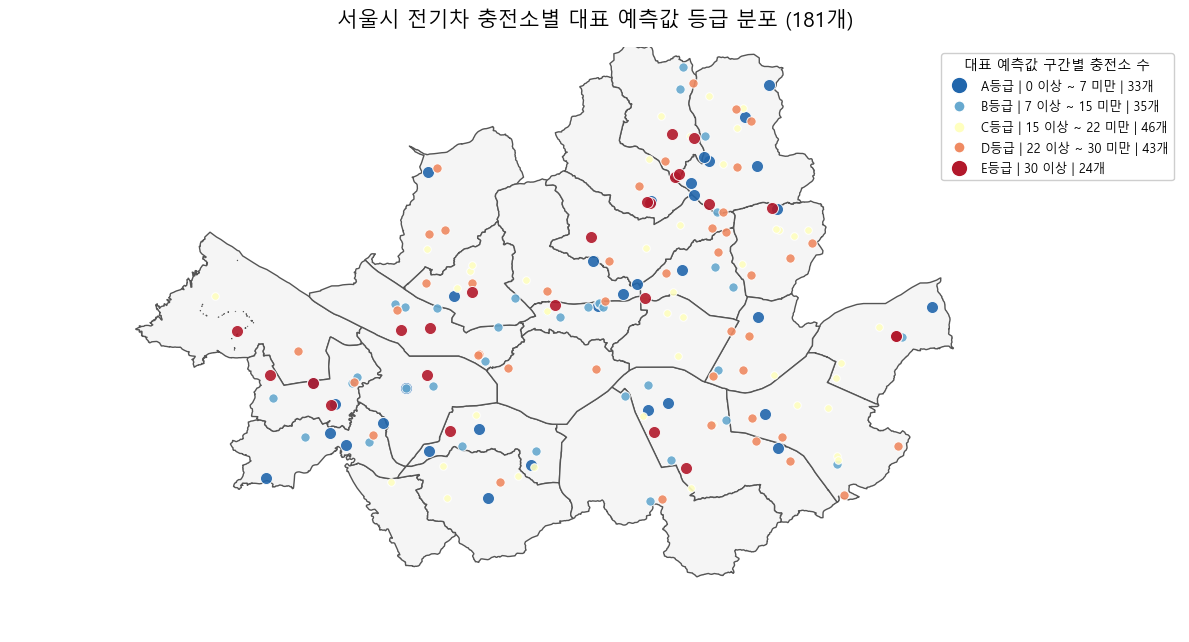


지도 이미지 저장 완료!
저장 위치: C:\test\08_지도시각화\서울시_충전소_등급별_행정구역지도.png
표시된 충전소 수: 181

등급별 충전소 개수:
A등급: 33개 (0 이상 ~ 7 미만)
B등급: 35개 (7 이상 ~ 15 미만)
C등급: 46개 (15 이상 ~ 22 미만)
D등급: 43개 (22 이상 ~ 30 미만)
E등급: 24개 (30 이상)


In [27]:
# =====================================
# 1. 라이브러리 및 기본 설정
# =====================================
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from pathlib import Path
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# =====================================
# 2. 파일 경로
# =====================================
location_path = Path(
    r"C:\test\08_지도시각화\서울시_충전소_위경도.xlsx"
)

grade_path = Path(
    r"C:\test\06_코드및노트북\충전소별_대표예측충전량_구간분류.xlsx"
)

output_path = Path(
    r"C:\test\08_지도시각화\서울시_충전소_등급별_행정구역지도.png"
)

# =====================================
# 3. 파일 존재 여부 확인
# =====================================
if not location_path.exists():
    raise FileNotFoundError(
        f"위치 파일을 찾을 수 없어:\n{location_path}"
    )

if not grade_path.exists():
    raise FileNotFoundError(
        f"등급 파일을 찾을 수 없어:\n{grade_path}"
    )

# =====================================
# 4. 데이터 불러오기
# =====================================
df_location = pd.read_excel(location_path)
df_grade = pd.read_excel(grade_path)

print("위치 데이터:", df_location.shape)
print("등급 데이터:", df_grade.shape)

print("위치 파일 열:", df_location.columns.tolist())
print("등급 파일 열:", df_grade.columns.tolist())

# =====================================
# 5. 충전소명 정리 및 데이터 연결
# =====================================
df_location["충전소명"] = (
    df_location["충전소명"].astype(str).str.strip()
)

df_grade["충전소명"] = (
    df_grade["충전소명"].astype(str).str.strip()
)

# 등급 파일에 필요한 열이 있는지 확인
required_grade_columns = [
    "충전소명", "대표 예측값", "등급"
]

missing_columns = [
    col for col in required_grade_columns
    if col not in df_grade.columns
]

if missing_columns:
    raise ValueError(
        f"등급 파일에 필요한 열이 없어: {missing_columns}"
    )

df_grade_map = df_grade[
    ["충전소명", "대표 예측값", "등급"]
].copy()

# 충전소명이 중복되면 첫 번째 행 사용
df_grade_map = df_grade_map.drop_duplicates(
    subset=["충전소명"]
)

# 충전소명 기준으로 위치와 등급 연결
df_map = df_location.merge(
    df_grade_map,
    on="충전소명",
    how="left"
)

# =====================================
# 6. 좌표 및 등급 데이터 정리
# =====================================
df_map["위도"] = pd.to_numeric(
    df_map["위도"], errors="coerce"
)

df_map["경도"] = pd.to_numeric(
    df_map["경도"], errors="coerce"
)

df_map["대표 예측값"] = pd.to_numeric(
    df_map["대표 예측값"], errors="coerce"
)

df_map["등급"] = (
    df_map["등급"].astype("string").str.strip()
)

# 좌표와 등급이 있는 데이터만 사용
df_plot = df_map.dropna(
    subset=["위도", "경도", "등급"]
).copy()

# 서울시 대략적인 좌표 범위
df_plot = df_plot[
    df_plot["위도"].between(37.4, 37.7)
    & df_plot["경도"].between(126.7, 127.3)
].copy()

# A~E 이외의 값 제거
df_plot = df_plot[
    df_plot["등급"].isin(["A", "B", "C", "D", "E"])
].copy()

if df_plot.empty:
    raise ValueError(
        "지도에 표시할 데이터가 없어. "
        "위도·경도와 충전소명 매칭 결과를 확인해 줘."
    )

print("\n지도 표시 대상 충전소:", len(df_plot))

# =====================================
# 7. 서울시 자치구 경계 데이터 불러오기
# =====================================
boundary_url = (
    "https://raw.githubusercontent.com/"
    "southkorea/seoul-maps/master/"
    "juso/2015/json/seoul_municipalities_geo.json"
)

try:
    seoul_gu = gpd.read_file(boundary_url)

    print("행정구역 데이터 열:", seoul_gu.columns.tolist())
    print("행정구역 도형 개수:", len(seoul_gu))

except Exception as e:
    raise RuntimeError(
        "서울시 자치구 경계 데이터를 불러오지 못했어. "
        "인터넷 접속이나 경계 데이터 주소를 확인해 줘."
    ) from e

# 좌표계가 지정되어 있지 않으면 경도·위도 좌표로 설정
if seoul_gu.crs is None:
    seoul_gu = seoul_gu.set_crs("EPSG:4326")

# 경계 데이터 좌표계 통일
seoul_gu = seoul_gu.to_crs("EPSG:4326")

# =====================================
# 8. 등급별 색상 및 예측값 구간
# =====================================
grade_colors = {
    "A": "#2166AC",  # 파랑
    "B": "#67A9CF",  # 하늘색
    "C": "#FFFFBF",  # 노랑
    "D": "#EF8A62",  # 주황
    "E": "#B2182B"   # 빨강
}

grade_ranges = {
    "A": "0 이상 ~ 7 미만",
    "B": "7 이상 ~ 15 미만",
    "C": "15 이상 ~ 22 미만",
    "D": "22 이상 ~ 30 미만",
    "E": "30 이상"
}

# 등급별 충전소 개수
grade_counts = (
    df_plot["등급"]
    .value_counts()
    .reindex(["A", "B", "C", "D", "E"], fill_value=0)
)

print("\n등급별 충전소 수:")
print(grade_counts)

# =====================================
# 9. 자치구 경계와 충전소 위치 그리기
# =====================================
fig, ax = plt.subplots(figsize=(12, 12))

# 서울시 자치구별 영역과 경계선
seoul_gu.plot(
    ax=ax,
    facecolor="#F5F5F5",
    edgecolor="#555555",
    linewidth=1.0,
    zorder=1
)

# 등급별 원 크기
# A, E등급을 크게 표시
grade_sizes = {
    "A": 75,
    "B": 45,
    "C": 30,
    "D": 45,
    "E": 75
}

# 등급별 충전소 위치 표시
for grade, color in grade_colors.items():

    subset = df_plot[
        df_plot["등급"] == grade
    ]

    ax.scatter(
        subset["경도"],
        subset["위도"],
        s=grade_sizes[grade],
        color=color,
        alpha=0.9,
        edgecolors="white",
        linewidths=0.7,
        zorder=3
    )

# =====================================
# 10. 범례: 등급 + 예측값 구간 + 충전소 수
# =====================================
legend_items = []

for grade, color in grade_colors.items():

    count = int(grade_counts[grade])

    legend_label = (
        f"{grade}등급 | "
        f"{grade_ranges[grade]} | "
        f"{count}개"
    )

    legend_items.append(
        Line2D(
            [0], [0],
            marker="o",
            color="w",
            markerfacecolor=color,
            markeredgecolor="white",
            markersize=(
                12 if grade in ["A", "E"] else 8
            ),
            label=legend_label
        )
    )

ax.legend(
    handles=legend_items,
    title="대표 예측값 구간별 충전소 수",
    loc="best",
    fontsize=9,
    title_fontsize=10,
    frameon=True,
    framealpha=0.95
)

# =====================================
# 11. 그래프 범위 및 제목
# =====================================
ax.set_xlim(126.7, 127.3)
ax.set_ylim(37.4, 37.7)

ax.set_title(
    f"서울시 전기차 충전소별 대표 예측값 등급 분포 ({len(df_plot)}개)",
    fontsize=15,
    pad=15
)

# 위도·경도 축과 숫자 제거
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([])
ax.set_yticks([])

# 축 테두리 제거
for spine in ax.spines.values():
    spine.set_visible(False)

# 격자 제거
ax.grid(False)

ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
# =====================================
# 12. 이미지 저장 및 화면 표시
# =====================================
plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n지도 이미지 저장 완료!")
print("저장 위치:", output_path)
print("표시된 충전소 수:", len(df_plot))

print("\n등급별 충전소 개수:")
for grade in ["A", "B", "C", "D", "E"]:
    print(
        f"{grade}등급: {grade_counts[grade]}개 "
        f"({grade_ranges[grade]})"
    )